In [1]:
import jax.numpy as jnp
from granad.periodic import Periodic
from granad import *
import matplotlib.pyplot as plt
import numpy as np

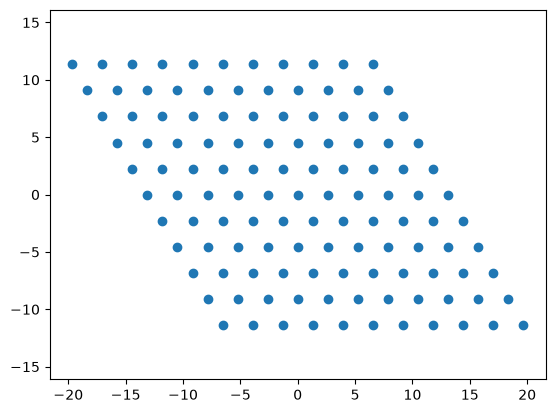

In [2]:
lattice_constant = 2.62 # Å
lattice_basis = [[1, 0, 0], [-0.5, jnp.sqrt(3)/2, 0]] 

au_s_hoppings = [-0.21077006 + 1.1, -0.5814]   # PARAMETERS TUNED MANUALLY TO FIT THE EXPECTED ENERGY BAND :)

goldene = (Material("Au")
        .lattice_constant(lattice_constant)  # Approximate lattice constant of hBN
        .lattice_basis(lattice_basis)
        .add_orbital_species("s_gold", atom='Au')
        .add_orbital(position=(0, 0), tag="Au_s", species="s_gold")
        .add_interaction(
            "hamiltonian",
            participants=("s_gold", "s_gold"),
            parameters=au_s_hoppings,  
        )   )

flake = goldene.cut_flake(Rectangle(0.5, 0.5), minimum_neighbor_number = 0)

lattice_vectors = lattice_constant*jnp.array([
    [1, 0, 0],
    [-0.5, jnp.sqrt(3)/2, 0] ])
fourier_cutoff = 4

bulk = Periodic(flake, lattice_vectors, fourier_cutoff)
bulk.show_2d(5)

In [3]:
ks = bulk.get_kgrid_monkhorst_pack([99, 99])
energies, vecs = bulk.get_eigenbasis(ks)

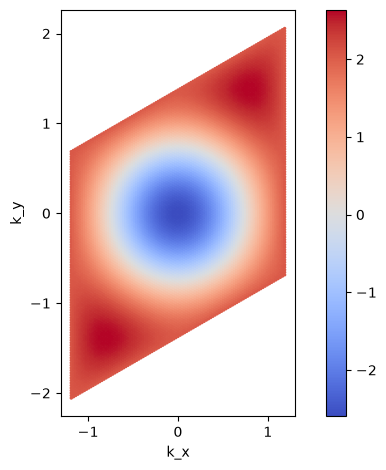

In [4]:
fig, ax = plt.subplots()
# for idx, k_value in enumerate(ks):
#     ax.scatter(k_value[0], k_value[1], c = energies[idx], s = 5)

ax.set_xlabel("k_x")
ax.set_ylabel("k_y")
plot1 = ax.scatter(ks[0, :], ks[1, :], c=energies, s=2, cmap="coolwarm", label="energy")
ax.set_aspect("equal")
plt.colorbar(plot1, ax=ax)

ax.set_aspect("equal")
plt.tight_layout()
plt.show()

In [5]:
mu_old = bulk.get_mu(energies)
print(f"Mu is {mu_old}")

for sigma in [0.01, 0.05, 0.1, 0.2, 0.3, 0.5]:
    mu_gauss = bulk.get_fermi_energy(energies, sigma=sigma, delta_e=1e-5)
    print(f"Mu Gauss with sigma {sigma} is {mu_gauss}")

Mu is 1.3784780901669267
Mu Gauss with sigma 0.01 is 1.3771699400097699
Mu Gauss with sigma 0.05 is 1.373729940012368
Mu Gauss with sigma 0.1 is 1.3710099400156257


KeyboardInterrupt: 